<a href="https://colab.research.google.com/github/jelianeys21/procesamiento-imagenes/blob/main/S6_PDIYVA_HSV-contorno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 72355  100 72355    0     0  1024k      0 --:--:-- --:--:-- --:--:-- 1009k


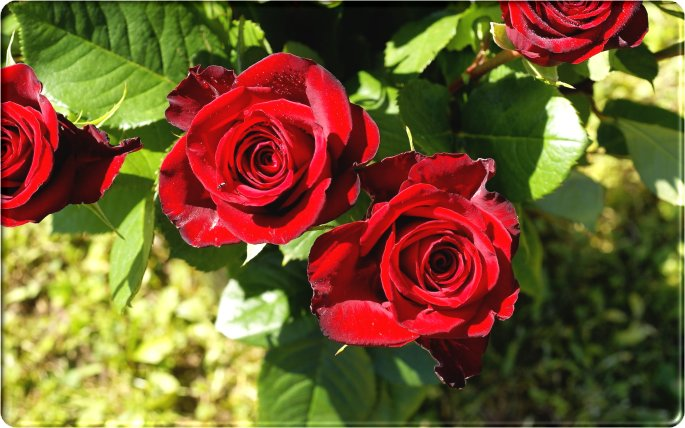

In [ ]:
!curl -o rosas https://raw.githubusercontent.com/giancarlo92/curso_pdi/main/imagenes/laboratorio1/rosas.jpg
rosas = cv2.imread("rosas")
cv2_imshow(rosas)

In [ ]:
!git clone https://github.com/giancarlo92/curso_pdi

fatal: destination path 'curso_pdi' already exists and is not an empty directory.


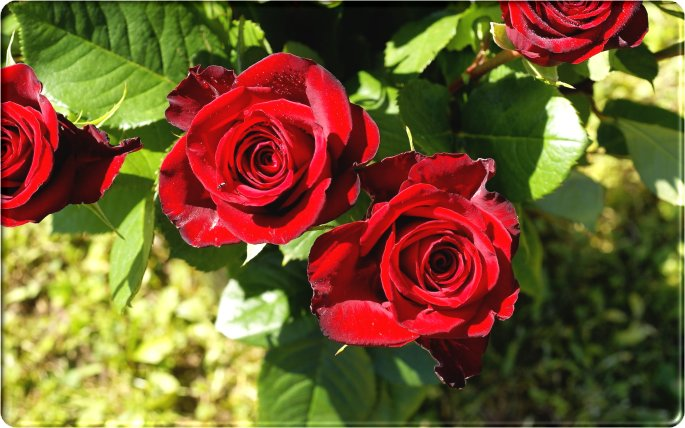

In [ ]:
imagen_rosas = cv2.imread('/content/curso_pdi/imagenes/clase6/rosas.jpg')
cv2_imshow(imagen_rosas)

**MODELO HSV**

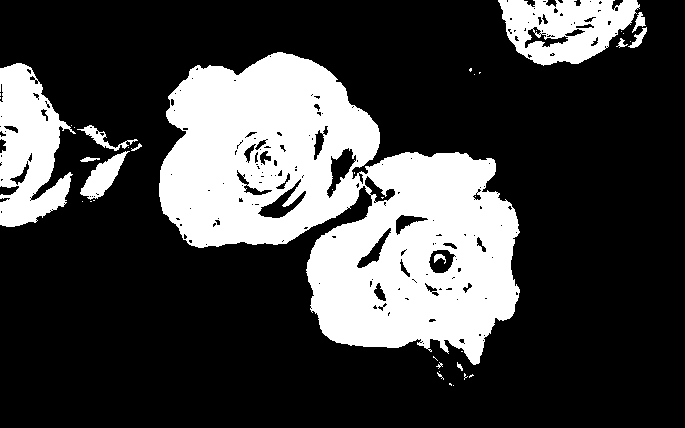

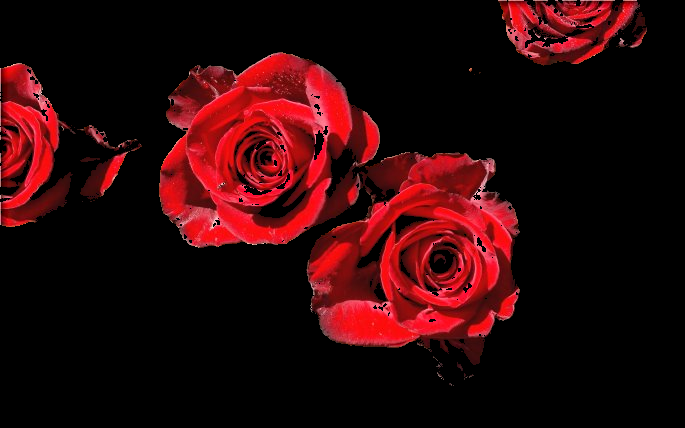

In [ ]:
# Hue (tonalidad), saturacion, value (S, V parametros para ajustar)
rojoBajo1 = np.array([0, 50, 50], np.uint8)
rojoAlto1 = np.array([8, 255, 255], np.uint8)
rojoBajo2 = np.array([175, 50, 50], np.uint8)
rojoAlto2 = np.array([180, 255, 255], np.uint8)
# BGR -> RGB
imagen_hsv = cv2.cvtColor(imagen_rosas, cv2.COLOR_BGR2HSV)
mascaraRoja1 = cv2.inRange(imagen_hsv, rojoBajo1, rojoAlto1)
mascaraRoja2 = cv2.inRange(imagen_hsv, rojoBajo2, rojoAlto2)
mascaraRoja = cv2.add(mascaraRoja1, mascaraRoja2)
deteccionRojo = cv2.bitwise_and(imagen_rosas, imagen_rosas, mask=mascaraRoja)
cv2_imshow(mascaraRoja)
cv2_imshow(deteccionRojo)

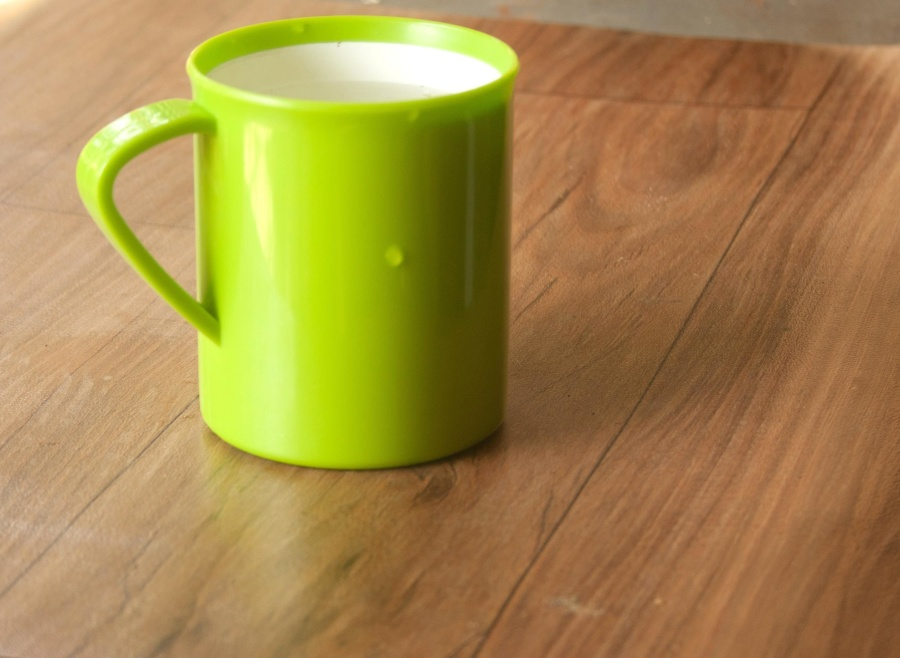

In [ ]:
taza_verde = cv2.imread('/content/curso_pdi/imagenes/clase6/tasa_verde.jpg')
cv2_imshow(taza_verde)

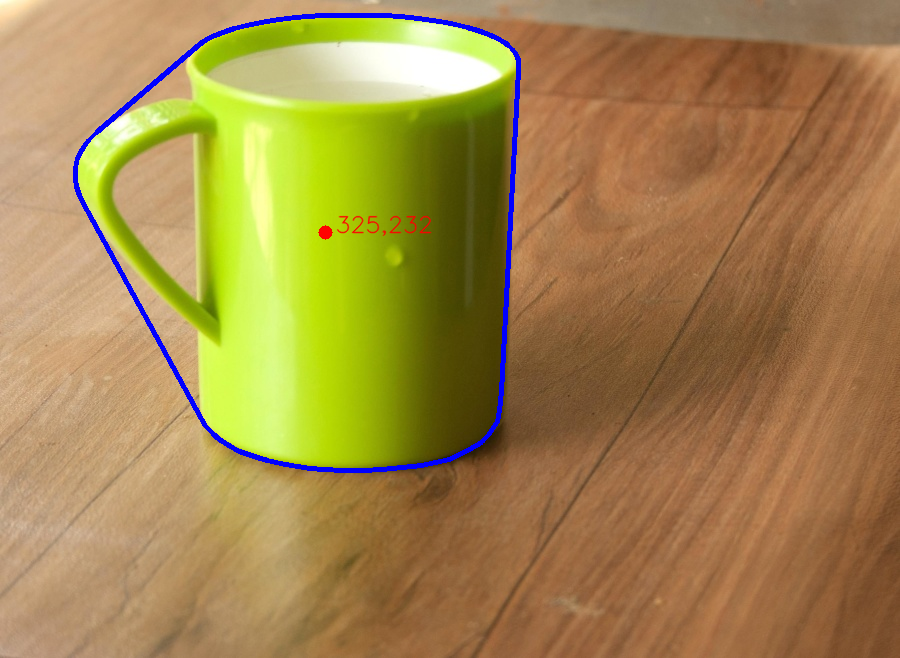

In [ ]:
verdeBajo1 = np.array([24, 0, 0], np.uint8)
verdeAlto1 = np.array([88, 255, 255], np.uint8)
imagen_hsv = cv2.cvtColor(taza_verde, cv2.COLOR_BGR2HSV)
mascaraVerde = cv2.inRange(imagen_hsv, verdeBajo1, verdeAlto1)
contorno, _ = cv2.findContours(mascaraVerde, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#drawContours(imagen_a_color, contorno, tipo_contorno, color_contorno, ancho_linea_contorno)
#BRG
for c in contorno:
  # calcular areaa
  area = cv2.contourArea(c)
  if area > 1000:
    # calcular el momento de inercia
    M = cv2.moments(c)
    # validacion para evitar que se haga una division entre 0
    if M["m00"] == 0: M["m00"] = 1
    # calculo de los puntos centrales
    x = int(M["m10"]/M["m00"])
    y = int(M["m01"]/M["m00"])
    # dibujar los puntos
    cv2.circle(taza_verde, (x, y), 7, (0, 0, 255), -1)
    # escribir en la imagen
    font = cv2.FONT_HERSHEY_SIMPLEX # word arial, calibri
    cv2.putText(taza_verde, '{},{}'.format(x, y), (x+10, y), font, 0.75, (0, 0, 255), 1, cv2.LINE_AA)
    # estilizar el contorno
    nuevoContorno = cv2.convexHull(c)
    cv2.drawContours(taza_verde, [nuevoContorno], -1, (255, 0, 0), 3)
#deteccionVerde = cv2.bitwise_and(taza_verde, taza_verde, mask=mascaraVerde)
cv2_imshow(taza_verde)